# Resource-Aware Crop Recommendation

**CS316 Introduction to AI and Data Science · Prince Sultan University · Term 261**
**Abdulrahman Alsohaibani (221110482)**

The goal is to recommend the best crop for a field from its soil and weather readings, and when several crops are suitable, prefer the one that needs less extra fertiliser and water.

The project supports SDG 2 (Zero Hunger), SDG 6 (Clean Water), SDG 12 (Responsible Consumption), SDG 13 (Climate Action).

Steps in this notebook:
1. Load the data
2. Clean the data and check outliers
3. Explore and visualise the data
4. Hypothesis testing
5. Normalisation and PCA
6. Train and compare models
7. Evaluate the best model
8. Sustainability step: resource-aware recommendation
9. Try it on a new field
10. Ethics and limitations
11. Conclusion

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import os
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Load the data

Crop Recommendation dataset (Kaggle, Atharva Ingle). Each row is one field:

| Column | Meaning |
|---|---|
| N, P, K | Nitrogen, Phosphorus, Potassium in the soil (kg/ha) |
| temperature | °C |
| humidity | % |
| ph | soil pH |
| rainfall | mm |
| label | the crop that grows well there (22 crops) |

In [29]:
df = pd.read_csv("data/crop_recommendation.csv")
print("Shape:", df.shape)
df.head()

Shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


To save memory: pandas stores every number as 64-bit and the crop name as text on every row. Smaller types are enough here: N, P, K are whole numbers up to 205 (int16), and the 22 crop names can be stored once as a category instead of being repeated on all 2,200 rows. The weather columns stay as float64 to keep full precision.

In [31]:
memory_before = df.memory_usage(deep=True).sum()

df = df.astype({"N": "int16", "P": "int16", "K": "int16", "label": "category"})

memory_after = df.memory_usage(deep=True).sum()
print(f"Memory before: {memory_before:,} bytes")
print(f"Memory after:  {memory_after:,} bytes")
print(f"Saved: {100 * (1 - memory_after / memory_before):.1f} %")

Memory before: 246,832 bytes
Memory after:  87,167 bytes
Saved: 64.7 %


## 2. Clean the data and check outliers

First check for missing values and duplicate rows.

In [32]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0


No missing values and no duplicates, so no rows need to be removed or filled.

Next, outliers using the IQR rule: a value is an outlier if it is below Q1 − 1.5·IQR or above Q3 + 1.5·IQR.

In [33]:
features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

for col in features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    is_outlier = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    top_crops = df.loc[is_outlier, "label"].astype(str).value_counts().head(2).to_dict()
    print(f"{col:12s} outliers: {is_outlier.sum():4d}   mostly: {top_crops}")

N            outliers:    0   mostly: {}
P            outliers:  138   mostly: {'apple': 70, 'grapes': 68}
K            outliers:  200   mostly: {'grapes': 100, 'apple': 100}
temperature  outliers:   86   mostly: {'papaya': 35, 'grapes': 34}
humidity     outliers:   30   mostly: {'chickpea': 30}
ph           outliers:   57   mostly: {'mothbeans': 42, 'chickpea': 13}
rainfall     outliers:  100   mostly: {'rice': 68, 'papaya': 17}


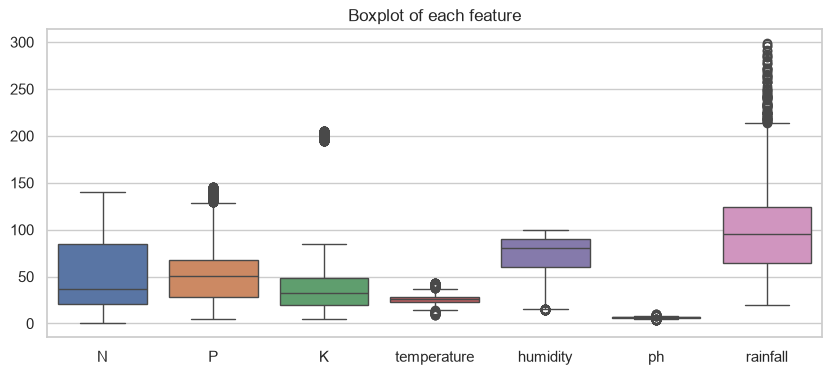

In [34]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[features])
plt.title("Boxplot of each feature")
plt.savefig("figures/fig1_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

We keep the outliers. They come from specific crops that really need extreme conditions, for example apple and grapes need very high potassium (K), and rice needs very high rainfall. Removing them would delete whole crops from the data.

## 3. Explore and visualise the data

In [35]:
df.describe().round(2)

,N,P,K,temperature,humidity,ph,rainfall
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56


Number of crops: 22
Rows per crop: min 100 max 100


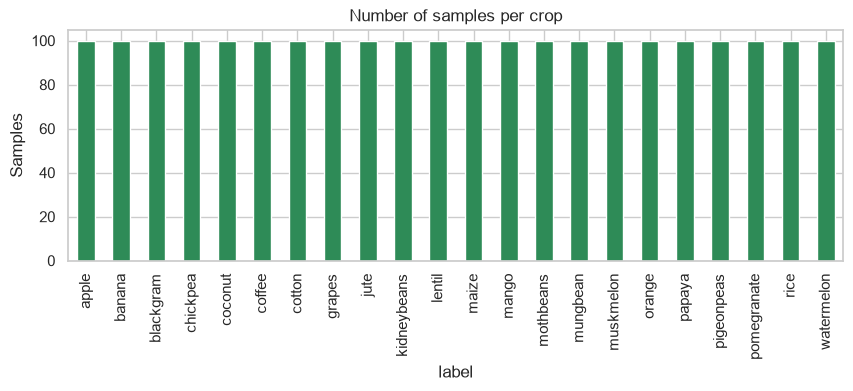

In [36]:
counts = df["label"].value_counts()
print("Number of crops:", len(counts))
print("Rows per crop: min", counts.min(), "max", counts.max())

counts.plot(kind="bar", figsize=(10, 3), color="seagreen")
plt.title("Number of samples per crop")
plt.ylabel("Samples")
plt.savefig("figures/fig2_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

The dataset is perfectly balanced: 100 rows for each of the 22 crops. That means plain accuracy is a fair way to compare models.

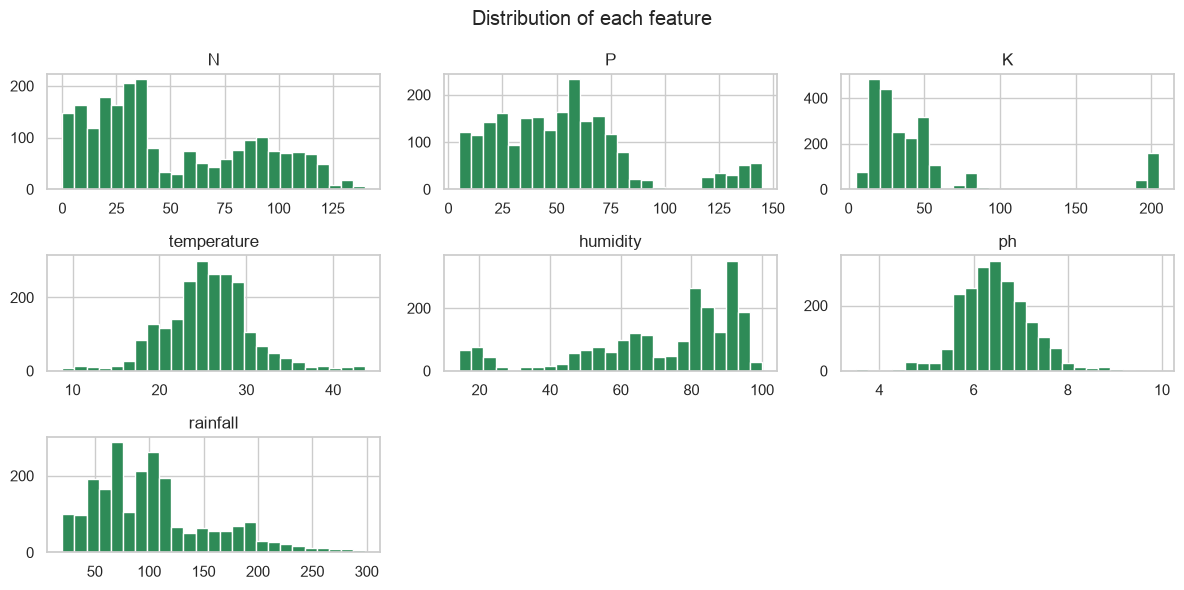

In [37]:
df[features].hist(figsize=(12, 6), bins=25, color="seagreen")
plt.suptitle("Distribution of each feature")
plt.tight_layout()
plt.savefig("figures/fig3_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

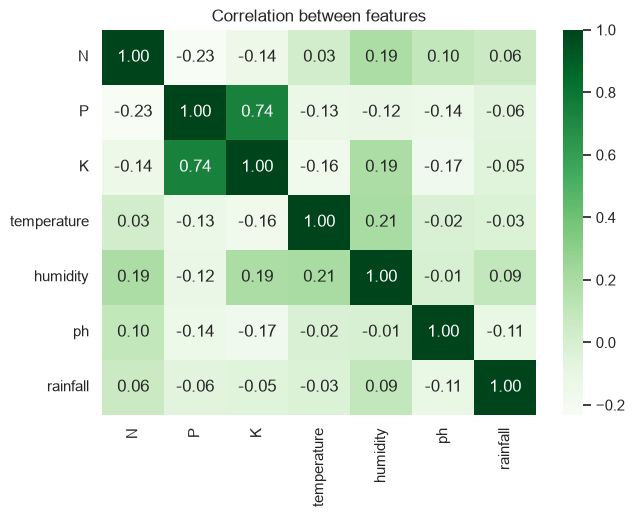

In [38]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="Greens")
plt.title("Correlation between features")
plt.savefig("figures/fig4_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

Most features are only weakly correlated, so each one adds new information. The only strong pair is P and K (r = 0.74), because the crops that need a lot of phosphorus (apple, grapes) also need a lot of potassium.

In [39]:
crop_means = df.groupby("label")[["N", "P", "K", "rainfall"]].mean().round(1)
crop_means.sort_values("rainfall", ascending=False).head(8)

,N,P,K,rainfall
label,,,,
rice,79.9,47.6,39.9,236.2
coconut,22.0,16.9,30.6,175.7
jute,78.4,46.9,40.0,174.8
coffee,101.2,28.7,29.9,158.1
pigeonpeas,20.7,67.7,20.3,149.5
papaya,49.9,59.0,50.0,142.6
apple,20.8,134.2,199.9,112.7
orange,19.6,16.6,10.0,110.5


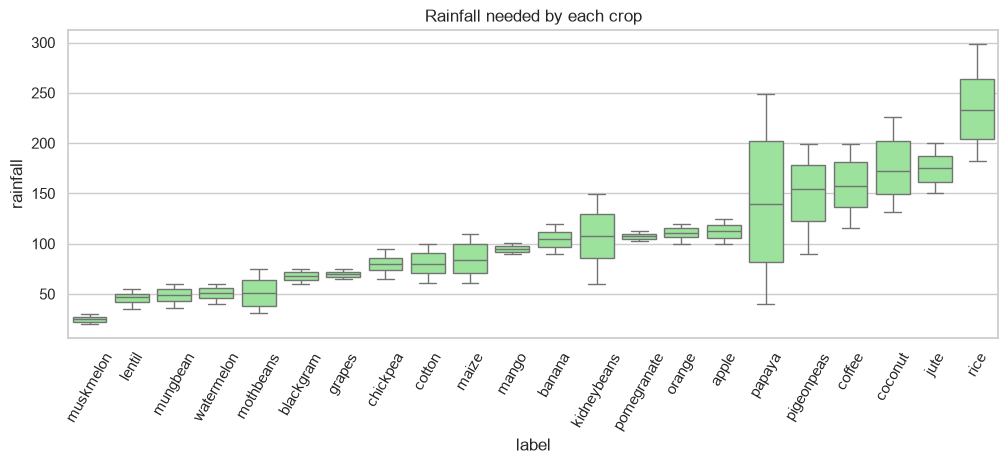

In [40]:
order = df.groupby("label")["rainfall"].median().sort_values().index
plt.figure(figsize=(12, 4))
sns.boxplot(data=df, x="label", y="rainfall", order=order, color="lightgreen")
plt.xticks(rotation=60)
plt.title("Rainfall needed by each crop")
plt.savefig("figures/fig5_rainfall_by_crop.png", dpi=150, bbox_inches="tight")
plt.show()

Crops need very different amounts of water: rice needs over 200 mm while crops like mothbeans and lentil need well under 60 mm. This difference is what the sustainability step in Section 8 uses.

## 4. Hypothesis testing

Question: does each feature really differ between crops, or could the differences be random?

We use a one-way ANOVA for each feature:
- H0: the mean of the feature is the same for all 22 crops
- H1: at least one crop has a different mean
- Significance level α = 0.05

In [41]:
groups = df.groupby("label")
results = []
for col in features:
    samples = [g[col].values for _, g in groups]
    f_stat, p_value = stats.f_oneway(*samples)
    results.append({"feature": col, "F": round(f_stat, 1), "p_value": p_value,
                    "reject_H0": p_value < 0.05})
pd.DataFrame(results)

,feature,F,p_value,reject_H0
0,N,897.6,0.000000e+00,True
1,P,1885.7,0.000000e+00,True
2,K,27238.4,0.000000e+00,True
3,temperature,102.2,3.210979e-305,True
4,humidity,3103.7,0.000000e+00,True
5,ph,60.3,6.493162e-199,True
6,rainfall,605.5,0.000000e+00,True


All p-values are far below 0.05 (a p-value shown as 0.0 is smaller than 10⁻³⁰⁰, too small for the computer to store), so we reject H0 for every feature. Every feature differs between crops, so all 7 are useful for prediction. We also ran 7 tests at once (multiple testing): even with the Bonferroni correction (α = 0.05 / 7 ≈ 0.007) every result is still significant.

## 5. Normalisation and PCA

Split the data first (80 % train, 20 % test, stratified so every crop is in both sets), then scale.
The scaler is fitted only on the training data so no information from the test set leaks into training.

In [42]:
X = df[features]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1760, 7)  Test: (440, 7)


The features have very different ranges (K goes up to 205, pH only up to 10). Distance-based models like k-NN and Logistic Regression would be dominated by the large numbers. After StandardScaler every feature has mean 0 and standard deviation 1.

PCA reduces the 7 features to 2 components so we can draw the data on a flat chart.

Variance explained by PC1 and PC2: [0.274 0.187]
Total: 0.461


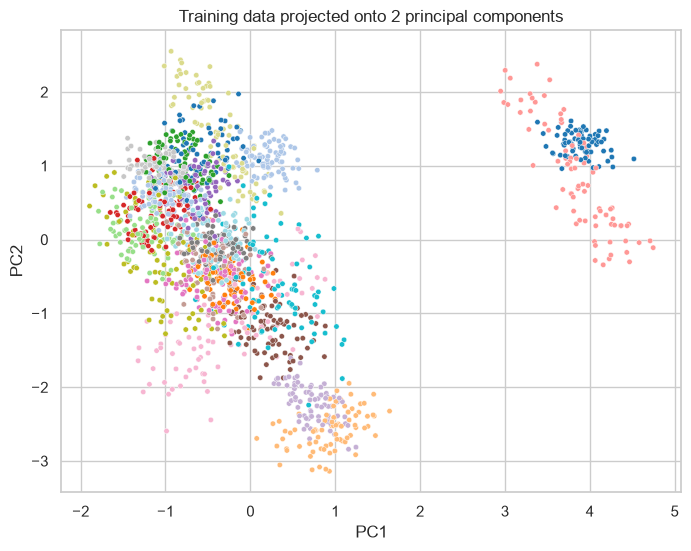

In [43]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)
print("Variance explained by PC1 and PC2:", pca.explained_variance_ratio_.round(3))
print("Total:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train.values, palette="tab20", s=15, legend=False)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Training data projected onto 2 principal components")
plt.savefig("figures/fig6_pca.png", dpi=150, bbox_inches="tight")
plt.show()

Two components keep only about half of the information, and many crops overlap in this 2D view. With only 7 features there is no need to reduce dimensions for training, so PCA is used for visualisation only and the models use all 7 scaled features.

## 6. Train and compare models

Five classification models from the course:

| Model | Idea |
|---|---|
| Logistic Regression | linear decision boundaries (extended from binary to many classes) |
| Naive Bayes | Bayes' theorem, assumes features are independent |
| k-Nearest Neighbours | predicts the crop of the 5 most similar fields |
| Decision Tree | splits the data using entropy (information gain) |
| Random Forest | 100 decision trees that vote |

Each model gets a 5-fold cross-validation score on the training set and a final score on the unseen test set.

In [44]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": GaussianNB(),
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(criterion="entropy", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

rows = []
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5)
    model.fit(X_train_scaled, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_test_scaled))
    rows.append({"model": name,
                 "cv_accuracy": round(cv_scores.mean(), 4),
                 "cv_std": round(cv_scores.std(), 4),
                 "test_accuracy": round(test_acc, 4)})

comparison = pd.DataFrame(rows).sort_values("test_accuracy", ascending=False)
comparison

,model,cv_accuracy,cv_std,test_accuracy
1,Naive Bayes,0.9943,0.0051,0.9955
4,Random Forest,0.9932,0.0043,0.9955
3,Decision Tree,0.9795,0.0077,0.9886
2,k-NN (k=5),0.9653,0.0075,0.9795
0,Logistic Regression,0.9676,0.0113,0.9727


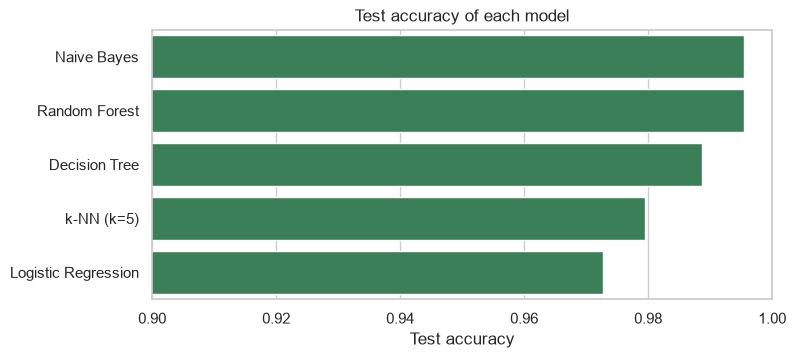

In [45]:
plt.figure(figsize=(8, 3.5))
sns.barplot(data=comparison, x="test_accuracy", y="model", color="seagreen")
plt.xlim(0.9, 1.0)
plt.xlabel("Test accuracy")
plt.ylabel("")
plt.title("Test accuracy of each model")
plt.savefig("figures/fig7_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Naive Bayes and Random Forest tie on the test set (99.55 %). To choose between them, check how confident each model is. Section 8 needs a model that can show when 2 or 3 crops are all suitable.

In [46]:
for name in ["Naive Bayes", "Random Forest"]:
    probs = models[name].predict_proba(X_test_scaled)
    print(f"{name:14s} average probability of its top crop: {probs.max(axis=1).mean():.3f}")

Naive Bayes    average probability of its top crop: 0.992
Random Forest  average probability of its top crop: 0.958


We chose the Random Forest. Naive Bayes gives its top crop about 99 % probability almost every time, because it assumes the features are independent (but P and K are strongly correlated, r = 0.74), which makes it over-confident. Random Forest has the same accuracy, is more stable than a single decision tree, and its probabilities show when a second crop is also a good option, which the sustainability step in Section 8 needs.

## 7. Evaluate the best model

In [47]:
best_model = models["Random Forest"]
y_pred = best_model.predict(X_test_scaled)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Correct:", (y_pred == y_test).sum(), "out of", len(y_test))
print()
print(classification_report(y_test, y_pred, digits=3))

Test accuracy: 0.9955
Correct: 438 out of 440

              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        20
      banana      1.000     1.000     1.000        20
   blackgram      1.000     0.950     0.974        20
    chickpea      1.000     1.000     1.000        20
     coconut      1.000     1.000     1.000        20
      coffee      1.000     1.000     1.000        20
      cotton      1.000     1.000     1.000        20
      grapes      1.000     1.000     1.000        20
        jute      0.952     1.000     0.976        20
 kidneybeans      1.000     1.000     1.000        20
      lentil      1.000     1.000     1.000        20
       maize      0.952     1.000     0.976        20
       mango      1.000     1.000     1.000        20
   mothbeans      1.000     1.000     1.000        20
    mungbean      1.000     1.000     1.000        20
   muskmelon      1.000     1.000     1.000        20
      orange      1.000     1.000 

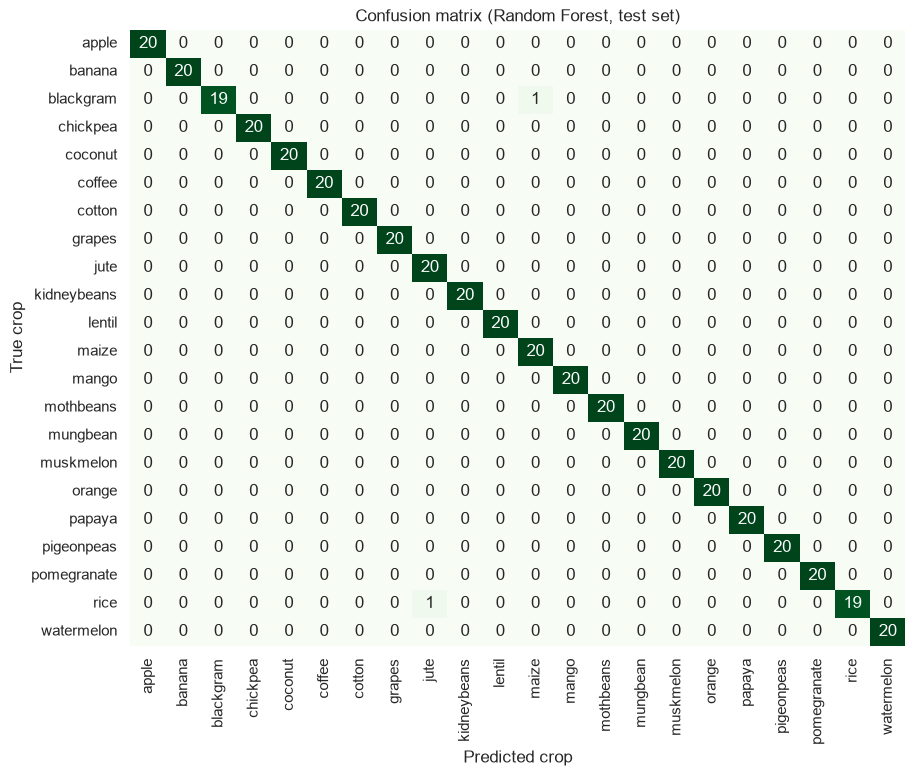

,true,predicted
789,blackgram,maize
83,rice,jute


In [48]:
labels = best_model.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=labels, yticklabels=labels, cbar=False)
plt.xlabel("Predicted crop")
plt.ylabel("True crop")
plt.title("Confusion matrix (Random Forest, test set)")
plt.savefig("figures/fig8_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

mistakes = pd.DataFrame({"true": y_test, "predicted": y_pred})
mistakes[mistakes["true"] != mistakes["predicted"]]

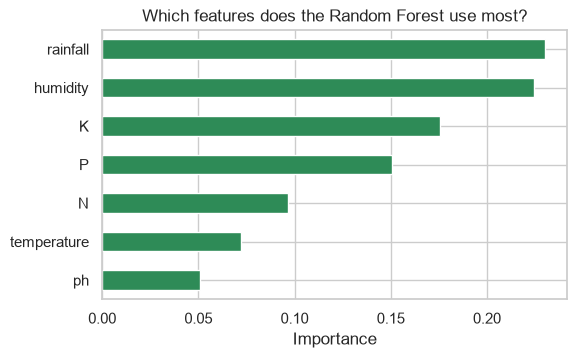

rainfall       0.230
humidity       0.224
K              0.175
P              0.151
N              0.096
temperature    0.072
ph             0.051
dtype: float64

In [49]:
importance = pd.Series(best_model.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", color="seagreen", figsize=(6, 3.5))
plt.title("Which features does the Random Forest use most?")
plt.xlabel("Importance")
plt.savefig("figures/fig9_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
importance.sort_values(ascending=False).round(3)

Almost every test field is classified correctly, and the few mistakes are between crops that grow in similar conditions. Rainfall, humidity and the soil nutrients matter most; temperature and pH matter less.

## 8. Sustainability step: resource-aware recommendation

A normal model just picks the crop with the highest probability. But that crop might need a lot of extra fertiliser or irrigation water that the field does not have.

The method:
1. Take the model's top 3 crops for the field (only crops with probability ≥ 10 %, the top crop is always allowed).
2. For each crop, compute how much the field is missing:
   - fertiliser gap = shortfall of N + P + K compared with what the crop typically needs
   - water gap = shortfall of rainfall compared with what the crop typically needs
3. Turn the gaps into a resource cost between 0 and 1.
4. Pick the crop with the best score = 0.5 × probability − 0.5 × resource cost.

"What the crop typically needs" = the median value of that crop in the training data.

In [50]:
train_df = X_train.copy()
train_df["label"] = y_train
crop_needs = train_df.groupby("label")[["N", "P", "K", "rainfall"]].median()

# gaps at or above these values count as full cost
FERT_SCALE = 250
WATER_SCALE = 120

def resource_gaps(field, crop):
    need = crop_needs.loc[crop]
    fert_gap = (max(need["N"] - field["N"], 0)
                + max(need["P"] - field["P"], 0)
                + max(need["K"] - field["K"], 0))
    water_gap = max(need["rainfall"] - field["rainfall"], 0)
    return fert_gap, water_gap

def resource_cost(fert_gap, water_gap):
    return 0.5 * min(fert_gap / FERT_SCALE, 1) + 0.5 * min(water_gap / WATER_SCALE, 1)

crop_needs.round(1).head()

,N,P,K,rainfall
label,,,,
apple,24.5,137.0,200.0,112.5
banana,101.0,81.5,50.0,105.2
blackgram,41.0,67.0,19.0,67.7
chickpea,39.0,68.0,79.0,79.2
coconut,24.5,15.0,30.5,171.9


In [51]:
def recommend(field, probs):
    top3 = np.argsort(probs)[::-1][:3]
    rows = []
    for rank, i in enumerate(top3):
        if rank > 0 and probs[i] < 0.10:
            continue
        crop = best_model.classes_[i]
        fert_gap, water_gap = resource_gaps(field, crop)
        cost = resource_cost(fert_gap, water_gap)
        rows.append({"crop": crop,
                     "probability": round(probs[i], 3),
                     "fertiliser_gap": round(fert_gap, 1),
                     "water_gap_mm": round(water_gap, 1),
                     "resource_cost": round(cost, 3),
                     "score": round(0.5 * probs[i] - 0.5 * cost, 3)})
    return pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)

Test it on all 440 test fields under two conditions:
- Normal: the real test data
- Dry season: the same fields with 50 % less rainfall, to simulate drought

For each case we compare the plain model's choice with the resource-aware choice.

In [52]:
def compare(X_fields):
    probs_all = best_model.predict_proba(scaler.transform(X_fields))
    rows = []
    for k in range(len(X_fields)):
        field = X_fields.iloc[k]
        table = recommend(field, probs_all[k])
        plain_crop = best_model.classes_[probs_all[k].argmax()]
        plain_fert, plain_water = resource_gaps(field, plain_crop)
        new = table.iloc[0]
        rows.append({"plain_crop": plain_crop, "new_crop": new["crop"],
                     "plain_fert_gap": plain_fert, "new_fert_gap": new["fertiliser_gap"],
                     "plain_water_gap": plain_water, "new_water_gap": new["water_gap_mm"]})
    return pd.DataFrame(rows)

X_dry = X_test.copy()
X_dry["rainfall"] = X_dry["rainfall"] * 0.5

summary = []
for name, fields in [("Normal", X_test), ("Dry season (rain x 0.5)", X_dry)]:
    res = compare(fields)
    summary.append({
        "scenario": name,
        "choice_changed_%": round(100 * (res["plain_crop"] != res["new_crop"]).mean(), 1),
        "plain_water_gap_mm": round(res["plain_water_gap"].mean(), 1),
        "new_water_gap_mm": round(res["new_water_gap"].mean(), 1),
        "plain_fert_gap": round(res["plain_fert_gap"].mean(), 1),
        "new_fert_gap": round(res["new_fert_gap"].mean(), 1),
    })
summary = pd.DataFrame(summary)
summary

,scenario,choice_changed_%,plain_water_gap_mm,new_water_gap_mm,plain_fert_gap,new_fert_gap
0,Normal,0.0,6.3,6.3,9.8,9.8
1,Dry season (rain x 0.5),20.2,45.3,32.1,9.8,12.3


Dry season: the recommendation changes for 20.2 % of fields
Average extra water needed drops from 45.3 mm to 32.1 mm (29 % less)


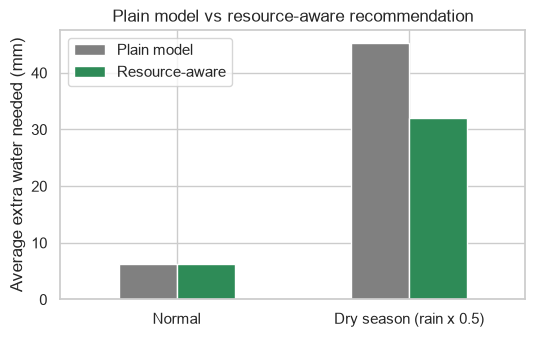

In [53]:
dry = summary.iloc[1]
water_saving = 100 * (dry["plain_water_gap_mm"] - dry["new_water_gap_mm"]) / dry["plain_water_gap_mm"]
print(f"Dry season: the recommendation changes for {dry['choice_changed_%']} % of fields")
print(f"Average extra water needed drops from {dry['plain_water_gap_mm']} mm to {dry['new_water_gap_mm']} mm "
      f"({water_saving:.0f} % less)")

summary.set_index("scenario")[["plain_water_gap_mm", "new_water_gap_mm"]].plot(
    kind="bar", color=["grey", "seagreen"], figsize=(6, 3.5), rot=0)
plt.legend(["Plain model", "Resource-aware"])
plt.xlabel("")
plt.ylabel("Average extra water needed (mm)")
plt.title("Plain model vs resource-aware recommendation")
plt.savefig("figures/fig10_water_saving.png", dpi=150, bbox_inches="tight")
plt.show()

With normal data the model is already very confident, so the top crop is almost always kept. In a dry season the model is less sure, and the resource-aware step switches some fields to a crop that is still suitable but needs much less irrigation water. The trade-off is that the new choice is sometimes not the crop with the highest probability.

## 9. Try it on a new field

A dry, warm field with little rain. Change the numbers to test any field.

In [54]:
new_field = pd.Series({"N": 36, "P": 26, "K": 26, "temperature": 30.2,
                       "humidity": 51.1, "ph": 6.8, "rainfall": 47.6})

probs = best_model.predict_proba(scaler.transform(new_field.to_frame().T))[0]
table = recommend(new_field, probs)

print("Plain model would choose:   ", best_model.classes_[probs.argmax()])
print("Resource-aware choice:      ", table.loc[0, "crop"])
table

Plain model would choose:    mango
Resource-aware choice:       mothbeans


,crop,probability,fertiliser_gap,water_gap_mm,resource_cost,score
0,mothbeans,0.44,21.0,1.8,0.049,0.195
1,mango,0.48,7.0,47.0,0.210,0.135


The plain model picks mango (48 %), but mango needs about 47 mm more water than this field gets. Mothbeans are almost as suitable (44 %) and need only about 2 mm extra, so the resource-aware step recommends mothbeans.

## 10. Ethics and limitations

- The data comes from Indian farms and every crop has exactly 100 rows. Real fields in Saudi Arabia have different soils and climates, so the model must be retrained on local data before real use.
- The farmer makes the final decision. The tool shows the probability and the resource gaps so the choice is transparent.
- Small farmers without soil sensors cannot use it, so a real system would need cheap soil tests or default regional values.
- Market prices, crop rotation and pests are not in the data.
- A wrong recommendation can cost a farmer a season, so predictions with low probability should be flagged.

## 11. Conclusion

- The data was clean (no missing values or duplicates). Outliers were kept because they belong to real crops.
- ANOVA showed that all 7 features differ significantly between crops.
- Random Forest and Naive Bayes tied at 99.55 % test accuracy. Random Forest was chosen because its probabilities are more useful for the sustainability step.
- The resource-aware step keeps the model's accuracy on normal data, and in a dry season recommends crops that need clearly less irrigation water, which supports SDGs 2, 6, 12 and 13.
- Future work could add local Saudi soil data, crop prices, and a simple mobile app for farmers.